# Deliverable 2 - Baseline Modelling and First Improvements

## Members:
- Mustafa Al-Youzbaki  
- Gabriel Burrows 
- Queenie Li 
- Michelle Shi 

# Baseline Model
- Build a simple, interpretable baseline model in scikit-learn (e.g., Linear Regression, Logistic Regression, Decision Tree, K-Nearest Neighbors, etc.).
- The baseline serves as your **benchmark** for later comparison.
- **Tip:** To explore options quickly, you may use an **AutoML tool such as AutoGluon** \
(https://auto.gluon.ai/stable/index.html) to identify promising algorithm families.
    - If you decide to follow this approach, make sure to document AutoML results briefly, but reproduce the main baseline using scikit-learn.
- Define and justify evaluation metric(s) appropriate for your task:
    - Regression → RMSE, MAE, R2, etc.
    - Classification → Accuracy, F1-score, Precision, Recall, AUC, etc.
- Report performance via **train–validation splits**. Apply stratification if needed (e.g., train_test_split(..., stratify = y)).
- Interpret whether your baseline appears to **underfit, overfit, or generalize well**, connecting to the **bias–variance trade-off** concept from the lectures.

### Initialize Data and Import Libraries
Source: [House Prices - Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview)

In [279]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score, cross_validate, KFold, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

# Import training data
train = pd.read_csv('train.csv')

target = 'SalePrice'
numeric_features = ['OverallQual', 'YearBuilt', 'TotalBsmtSF', 'GrLivArea']

X = train[numeric_features]
y = train[target]

train[numeric_features + [target]].describe()

,OverallQual,YearBuilt,TotalBsmtSF,GrLivArea,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,6.099315,1971.267808,1057.429452,1515.463699,180921.195890
std,1.382997,30.202904,438.705324,525.480383,79442.502883
min,1.000000,1872.000000,0.000000,334.000000,34900.000000
25%,5.000000,1954.000000,795.750000,1129.500000,129975.000000
50%,6.000000,1973.000000,991.500000,1464.000000,163000.000000
75%,7.000000,2000.000000,1298.250000,1776.750000,214000.000000
max,10.000000,2010.000000,6110.000000,5642.000000,755000.000000


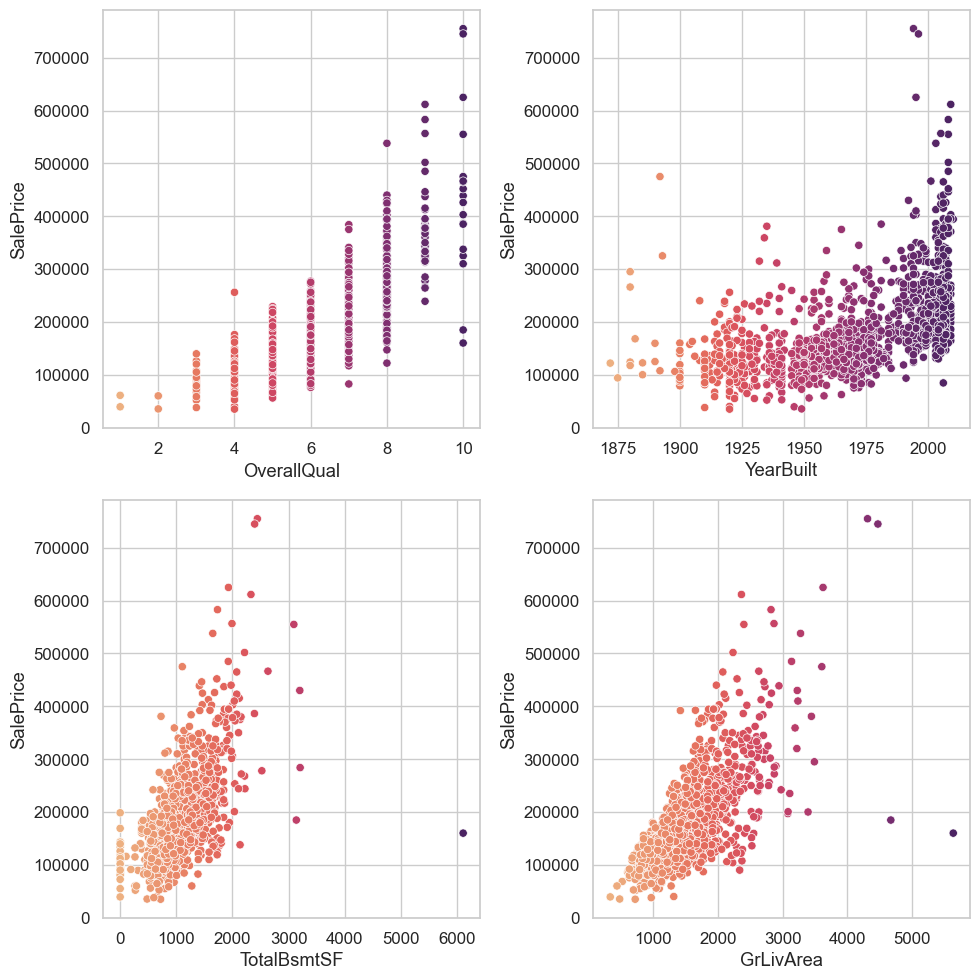

In [280]:
# Set up grid layout
n = len(numeric_features)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.scatterplot(x=train[feature],
                        y=train[target],
                        hue=train[feature],
                        ax=axes[i],
                        palette="flare",
                        legend=False
        )
    


plt.tight_layout()
plt.show()

### Linear Regression

In [281]:
# Train-validation split
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# Predictions
y_pred_train = lr.predict(X_train_scaled)
y_pred_valid = lr.predict(X_valid_scaled)

In [282]:
# Evaluation metrics
def eval_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

train_rmse, train_mae, train_r2 = eval_metrics(y_train, y_pred_train)
valid_rmse, valid_mae, valid_r2 = eval_metrics(y_valid, y_pred_valid)

print(f"Train RMSE: {train_rmse:.0f} | Valid RMSE: {valid_rmse:.0f}")
print(f"Train MAE: {train_mae:.0f} | Valid MAE: {valid_mae:.0f}")
print(f"Train R2: {train_r2:.3f} | Valid R2: {valid_r2:.3f}")

Train RMSE: 38866 | Valid RMSE: 40266
Train MAE: 24772 | Valid MAE: 25694
Train R2: 0.747 | Valid R2: 0.789


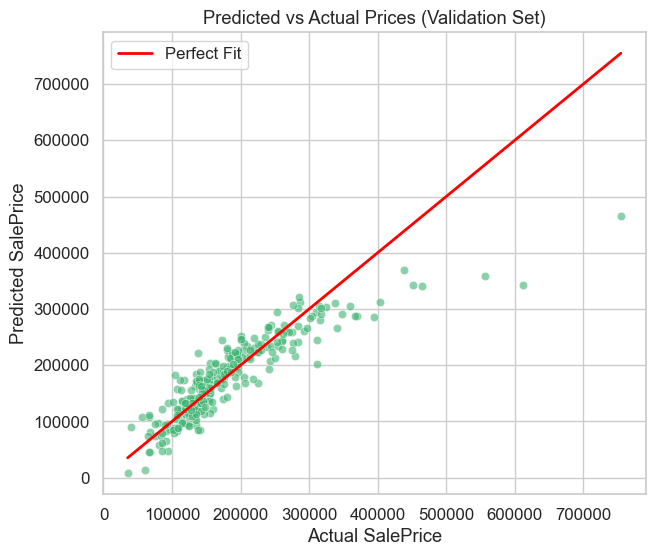

In [283]:
# Predicted vs Actual
plt.figure(figsize=(7,6))
sns.scatterplot(x=y_valid, y=y_pred_valid, alpha=0.6, color="mediumseagreen")
sns.lineplot(x=y_valid, y=y_valid, color="red", lw=2, label="Perfect Fit")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Predicted vs Actual Prices (Validation Set)")
plt.legend()
plt.show()

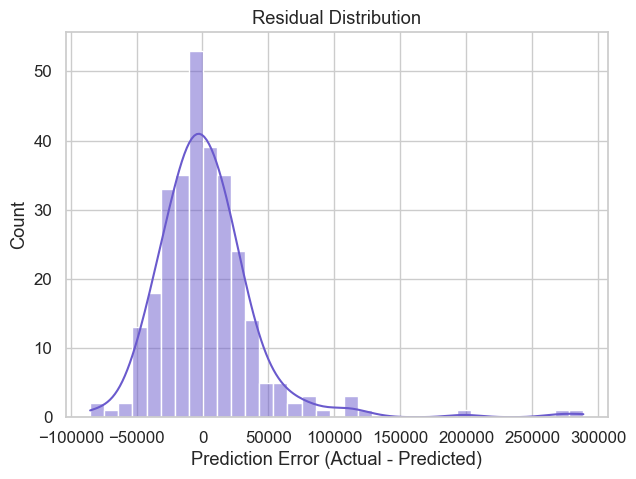

In [284]:
# Residuals Histogram
residuals = y_valid - y_pred_valid
plt.figure(figsize=(7,5))
sns.histplot(residuals, kde=True, color="slateblue")
plt.title("Residual Distribution")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.show()

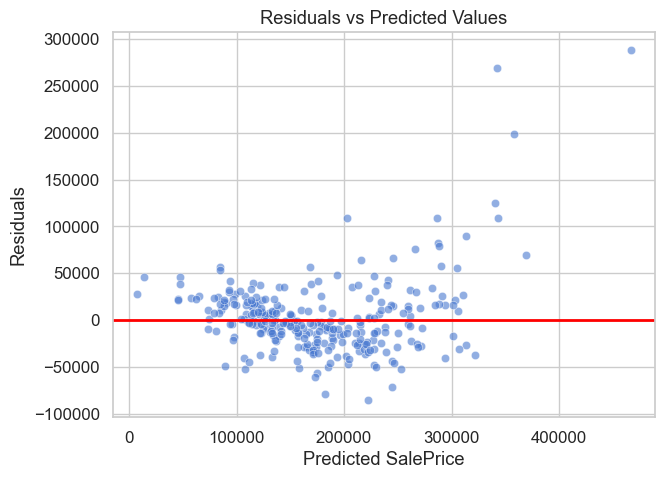

In [285]:
# Residuals vs Predicted
plt.figure(figsize=(7,5))
sns.scatterplot(x=y_pred_valid, y=residuals, alpha=0.6)
plt.axhline(0, color='red', lw=2)
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted SalePrice")
plt.ylabel("Residuals")
plt.show()

# Cross-Validation
- In this deliverable, cross-validation is used solely to evaluate and compare models, \
not to tune hyperparameters (which will be covered in Deliverable 3).
- Use cross_val_score and/or cross_validate to perform **k-fold cross-validation** \
(typically k = 5 or 10). Apply stratification if needed (e.g., using StratifiedKFold()).
- Report the **mean and standard deviation** of the chosen metric across folds.
- Compare these with the single train–validation results and explain differences.
- Discuss model stability and generalization.

In [286]:
# 10-Fold CV
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

scoring = {
    'RMSE': 'neg_root_mean_squared_error',  # negative because sklearn convention
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

cv_lr = cross_validate(lr, X, y, cv=kfold, scoring=scoring, return_train_score=True)

# Summarize CV
cv_summary = pd.DataFrame([{
    'Model': 'Linear Regression',
    'Train RMSE Mean': -np.mean(cv_lr['train_RMSE']),
    'Train RMSE Std': np.std(cv_lr['train_RMSE']),
    'Valid RMSE Mean': -np.mean(cv_lr['test_RMSE']),
    'Valid RMSE Std': np.std(cv_lr['test_RMSE']),
    'Valid MAE Mean': -np.mean(cv_lr['test_MAE']),
    'Valid R2 Mean': np.mean(cv_lr['test_R2']),
    'Valid R2 Std': np.std(cv_lr['test_R2'])
}]).round(2)

display(cv_summary)

,Model,Train RMSE Mean,Train RMSE Std,Valid RMSE Mean,Valid RMSE Std,Valid MAE Mean,Valid R2 Mean,Valid R2 Std
0,Linear Regression,39022.75,1015.41,39002.47,8480.14,25102.96,0.74,0.13


In [287]:
comparison_lr = pd.DataFrame({
    'Metric': ['Train RMSE', 'Valid RMSE', 'Train R2', 'Valid R2'],
    'Single Split': [train_rmse, valid_rmse, train_r2, valid_r2],
    'CV Mean': [
        cv_summary.loc[0, 'Train RMSE Mean'],
        cv_summary.loc[0, 'Valid RMSE Mean'],
        train_r2,
        cv_summary.loc[0, 'Valid R2 Mean']
    ],
    'CV Std': [
        cv_summary.loc[0, 'Train RMSE Std'],
        cv_summary.loc[0, 'Valid RMSE Std'],
        np.nan,
        cv_summary.loc[0, 'Valid R2 Std']
    ]
})

display(comparison_lr)

,Metric,Single Split,CV Mean,CV Std
0,Train RMSE,38865.530570,39022.750000,1015.41
1,Valid RMSE,40265.682398,39002.470000,8480.14
2,Train R2,0.746749,0.746749,NaN
3,Valid R2,0.788624,0.740000,0.13


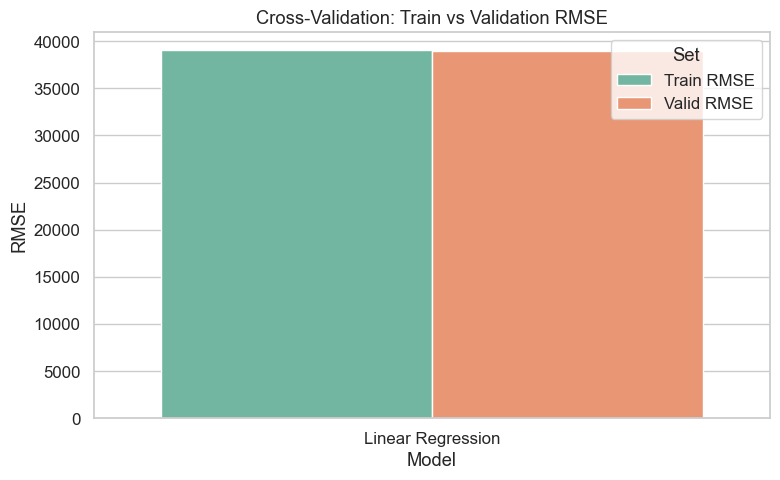

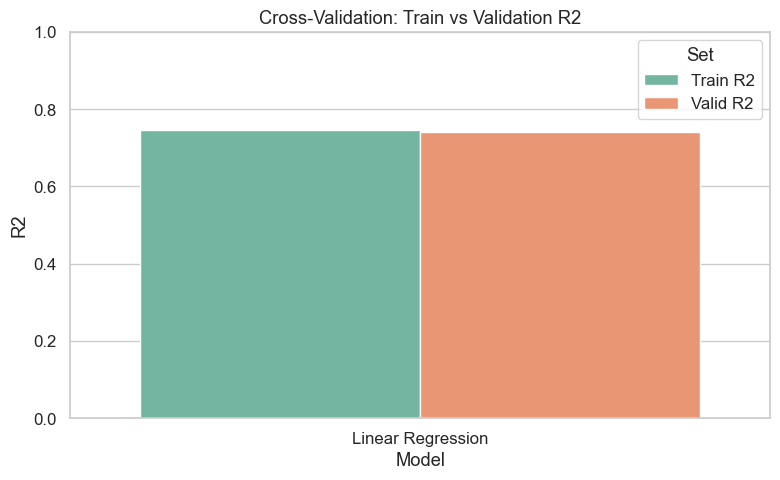

In [288]:
# RMSE side-by-side bars
cv_plot = cv_summary.melt(
    id_vars='Model',
    value_vars=['Train RMSE Mean', 'Valid RMSE Mean'],
    var_name='Set',
    value_name='RMSE'
)
cv_plot['Set'] = cv_plot['Set'].str.replace(' Mean','')

plt.figure(figsize=(8,5))
sns.barplot(
    data=cv_plot,
    x='Model',
    y='RMSE',
    hue='Set',       # separates Train vs Valid bars
    palette='Set2',
    errorbar=None
)
plt.title("Cross-Validation: Train vs Validation RMSE")
plt.ylabel("RMSE")
plt.tight_layout()
plt.show()

# R2 side-by-side bars
# Ensure 'Train R2 Mean' exists
if 'Train R2 Mean' not in cv_summary.columns:
    cv_summary['Train R2 Mean'] = train_r2  # placeholder

cv_plot_r2 = cv_summary.melt(
    id_vars='Model',
    value_vars=['Train R2 Mean', 'Valid R2 Mean'],
    var_name='Set',
    value_name='R2'
)
cv_plot_r2['Set'] = cv_plot_r2['Set'].str.replace(' Mean','')

plt.figure(figsize=(8,5))
sns.barplot(
    data=cv_plot_r2,
    x='Model',
    y='R2',
    hue='Set',
    palette='Set2',
    errorbar=None
)
plt.title("Cross-Validation: Train vs Validation R2")
plt.ylabel("R2")
plt.ylim(0,1)
plt.tight_layout()
plt.show()

# Error Analysis and Model Diagnostics

- Include at least one **diagnostic visualization** from the lectures, such as:
    - **Prediction Error / Residual Plot or Partial Dependence Plot (PDP)** (for regression)
    - **Confusion Matrix, Decision Boundary Plot,** or **ROC Curve** (for classification)
- Discuss what each visualization reveals: e.g., patterns of error, outliers, class imbalance, or non-linearity.
- If you spot systematic errors, mention potential remedies for Deliverable 3

# First Improvement(s)

- Implement at least one meaningful improvement. You may combine several small ones.

### Possible directions (choose ≥ 1):
### A- Preprocessing Enhancements such as:
- Scaling (e.g., StandardScaler, MinMaxScaler)
- Encoding categorical features (e.g., OneHotEncoder)
- Handling missing values (e.g., SimpleImputer, KNNImputer)
### B- Feature-Level Enhancements such as:
- **Feature Transformation:** e.g., Apply log, square-root, or standardization
transformations to reduce skewness or stabilize variance.
- **Feature Selection:** e.g., Remove redundant or uninformative features (e.g.,
SelectKBest, Recursive Feature Elimination, model-based importance).
- **Feature Engineering:** Create new informative features (e.g., ratios, interactions,
aggregations).
### C- Model-Level Enhancements such as:
- Adjust **hyperparameters** (e.g., number of neighbours, regularization strength) to
explore model behaviour without full grid search.
- Try **non-linear methods** instead of linear ones (e.g., Decision Tree or KNN in
place of Linear/Logistic Regression).
- Compare linear vs. non-linear results to understand bias–variance trade-offs
and model capacity.
### D- Regularization Techniques such as:
- Apply **LASSO, Ridge,** or **Elastic Net** regression to control model complexity and
reduce overfitting.
- Discuss how regularization affects the bias–variance trade-off and interpret the
resulting coefficients.
### E- Data-Level Enhancements such as:
- **Handling Imbalanced Classes:** Use oversampling (e.g., SMOTE),
undersampling, or class-weight adjustments to improve recall and F1-score.
- **Outlier Treatment:** Identify and handle outliers (e.g., IQR filtering, Z-score
thresholds) to prevent extreme values from distorting results.
### F- Unsupervised Enhancement (Optional)
- Apply **dimensionality reduction** (e.g., PCA) to simplify the feature space and
reduce correlation among features.
### For each implemented improvement:
- Explain the motivation and hypothesis.
- Show implementation code and results.
- Compare performance with the baseline using the same cross-validation procedure.
- Discuss whether it improves generalization and its effect on bias/variance.

# Discussion and Reflection

- Summarize key findings from baseline vs. improved models.
- Comment on any observable trade-offs (e.g., variance reduction at the cost of a
slight bias).
- **Explicitly describe how your team incorporated TA feedback from Deliverable 1.**
    - Summarize the feedback points received and explain how each was
    addressed or implemented in this submission.
    - Show clear evidence of acting on feedback is required for full marks.
- Conclude with your potential next steps for Deliverable 3 (systematic tuning and
model selection).


# Individual Contributions
## Who Did What


| Group Member | Role |
| --- | --- |
| Mustafa Al-Youzbaki  | ~ |
| Gabriel Burrows | ~ |
| Queenie Li | ~ |
| Michelle Shi  | ~ |

## Checklist

- [ ] **Dataset files included** and notebook runs without modification on TA machines.
- [ ] **Baseline model clearly defined, interpreted** and justified with correct metrics and reasoning.
- [ ] **Cross-validation implemented** correctly for model evaluation (not tuning) and interpreted.
- [ ] **At least one diagnostic plot included** (e.g., residuals, ROC curve, confusion matrix, or PDP) with meaningful interpretation.
- [ ] **At least one improvement implemented**, may include:
    - Preprocessing (scaling, encoding, missing values)
    - Feature-Level Enhancements (transformation, selection, engineering)
    - Model-Level Enhancements (non-linear model, parameter adjustment)
    - Regularization (LASSO, Ridge, Elastic Net)
    - Data-Level Enhancements (handling imbalance, outliers)

- [ ] **Performance comparison provided** between baseline and improved model using the same CV procedure.
- [ ] **TA feedback from Deliverable 1 documented:** list main points received and describe how each was addressed

- [ ] **Discussion and reflection included** with clear insights about results, trade-offs, and next steps for Deliverable 3.
- [ ] **Group contributions table completed**, showing each member’s specific role.
- [ ] **All required files submitted:**
    - project_deliverable_2_Group_#.ipynb (fully runnable)
    - project_deliverable_2_Group_#.pdf (export of notebook)
    - data/ folder containing all necessary dataset files.


## Feedback → Changes Log

### Feedback
| Criterion | Assessment | Score |
| --- | --- | --- |
| 1 Dataset Justification  | Excellent justification. States clear motivation—predictive modelling interest, economic relevance, and structured numeric/categorical mix suitable for learning regression and preprocessing. Connects challenge to skill development. | Excellent  |
| 2 Data Dictionary | Comprehensive and accurate feature documentation. Clarifies variable roles (ordinal vs. nominal vs. numeric). A few lesser-used variables could use short notes, but coverage is 90 %+. | Excellent  |
| 3 Exploratory Data Analysis | Very strong EDA: dataset size + info() summary; descriptive stats; clear correlation exploration; detailed scatterplots for top predictive features; sound outlier detection via z-score; missing-value audit table; meaningful interpretation. Minor improvement: annotate figures with axis labels + add textual summaries under each plot. | Excellent  |
| 4 Challenges & Strategies | Outstanding discussion of all major preprocessing challenges: missingness, skewness, outliers, multicollinearity, high dimensionality, scaling, rare categories. Each issue linked to a concrete solution (median imputation, log transform, encoding, standardization). Logical and technically correct. | Excellent  |
| 5 Notebook Quality & Individual Contributions  | Notebook is cleanly organized with headings and readable code blocks. Team roles (Mustafa – Challenges/Strategies, Gabriel – Dictionary/Visuals, Queenie – Justification, Michelle – EDA & Explanation) are clearly documented. Minor formatting inconsistencies only. | Excellent  |

### Changes
